# Figure S2 — mixed hiPSC–K562 Parse v3 compatibility panels

This notebook reproduces **Figure S2 panels i, j, l, m, and n** from the mixed hiPSC–K562 Parse Evercode v3 experiment. Other Figure S2 panels are based on separate benchmarking experiments and are not included here.

The analysis reads the Split-pipe expression matrix, long guide-UMI table, filtered guide reference, and transcript-saturation reports for the CS1, DC1, Dual, and no-guide-primer conditions.


In [1]:
# Repository-path bootstrap for local support modules.
from pathlib import Path
import sys


def _find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "cc_perturbseq").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root containing src/cc_perturbseq. "
        "Run this notebook from within the repository checkout."
    )


REPO_ROOT = _find_repo_root()
for _path in (REPO_ROOT, REPO_ROOT / "src"):
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))
print("Repository:", REPO_ROOT)


Repository: /oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction


In [2]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display

from src.cc_perturbseq.figure_notebook import (
    initialize_figure,
    panel_directory,
    sha256_file,
    write_receipt,
)
from src.cc_perturbseq.figure_s02_parse_mix import (
    CAPTURE_PRIMER_ORDER,
    CELL_TYPE_ORDER,
    MANUSCRIPT_TRANSCRIPT_ORDER,
    PRIMER_ORDER,
    SOURCE_NOTEBOOK,
    plot_panel_i,
    plot_panel_j,
    plot_panel_l,
    plot_panel_m,
    plot_panel_n,
    prepare_parse_mix_benchmark,
)

FIGURE = {
    "figure_id": "Figure_S02",
    "title": "Figure S2 — Development and benchmarking of CC-Perturb-seq",
    "scope": "Panels i, j, l, m and n only — mixed hiPSC–K562 Parse v3 experiment",
    "manuscript": "Working CC-Perturb-seq EC Differentiation - Text V3",
    "panels": [
        {
            "panel": "i",
            "description": "Matched-pool guide recovery by transcriptomic cell type and primer",
            "type": "code",
            "required_inputs": [],
            "candidate_sources": [SOURCE_NOTEBOOK],
        },
        {
            "panel": "j",
            "description": "Guide-pool specificity by transcriptomic cell type and primer",
            "type": "code",
            "required_inputs": [],
            "candidate_sources": [SOURCE_NOTEBOOK],
        },
        {
            "panel": "l",
            "description": "Top-guide UMI capture including the no-guide-primer control",
            "type": "code",
            "required_inputs": [],
            "candidate_sources": [SOURCE_NOTEBOOK],
        },
        {
            "panel": "m",
            "description": "Transcriptome UMI recovery and read-depth saturation",
            "type": "code",
            "required_inputs": [],
            "candidate_sources": [SOURCE_NOTEBOOK],
        },
        {
            "panel": "n",
            "description": "hiPSC-pool versus K562-pool guide mixing after the 3-UMI cell-guide filter",
            "type": "code",
            "required_inputs": [],
            "candidate_sources": [SOURCE_NOTEBOOK],
        },
    ],
}
ctx = initialize_figure(FIGURE)

scope_config_path = REPO_ROOT / "config" / "figure_s02_parse_mix.yaml"
scope_config = yaml.safe_load(scope_config_path.read_text(encoding="utf-8"))
EXPERIMENT_ROOT = Path(
    os.environ.get(
        scope_config["override_environment_variable"],
        scope_config["experiment_root"],
    )
).expanduser()
SOURCE_NOTEBOOK_LABEL = SOURCE_NOTEBOOK  # provenance only; never opened


def export_matplotlib(figure, panel, stem):
    out = panel_directory(ctx, panel)
    result = {}
    for suffix in ("pdf", "svg", "png"):
        path = out / f"{stem}.{suffix}"
        kwargs = {"dpi": 300} if suffix == "png" else {}
        figure.savefig(
            path,
            bbox_inches="tight",
            facecolor="white",
            transparent=False,
            **kwargs,
        )
        result[suffix] = str(path)
    return result


display(
    {
        "scope": FIGURE["scope"],
        "experiment_root": str(EXPERIMENT_ROOT),
        "source_notebook": SOURCE_NOTEBOOK_LABEL,
        "source_notebook_sha256": "404daf543b4b333cf0fcbf3e553a30fad6895dc38382a27bd492f72e0d4eadb2",
        "configuration": str(scope_config_path),
        "environment_override": scope_config["override_environment_variable"],
    }
)
ctx["panels"]


{'scope': 'Panels i, j, l, m and n only — mixed hiPSC–K562 Parse v3 experiment',
 'experiment_root': '/oak/stanford/groups/engreitz/Users/tri/Perturb-Seq/analysis/250730_eTN10_Parsev3_mixediPSC_K562',
 'source_notebook': 'K562_hiPSC_ParseV3_plotnine_figure_reproduction.ipynb',
 'source_notebook_sha256': '404daf543b4b333cf0fcbf3e553a30fad6895dc38382a27bd492f72e0d4eadb2',
 'configuration': '/oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction/config/figure_s02_parse_mix.yaml',
 'environment_override': 'CCPERTURBSEQ_FIGURE_S02_ROOT'}

,panel,description,type,required_inputs,candidate_sources
0,i,Matched-pool guide recovery by transcriptomic ...,code,[],[K562_hiPSC_ParseV3_plotnine_figure_reproducti...
1,j,Guide-pool specificity by transcriptomic cell ...,code,[],[K562_hiPSC_ParseV3_plotnine_figure_reproducti...
2,l,Top-guide UMI capture including the no-guide-p...,code,[],[K562_hiPSC_ParseV3_plotnine_figure_reproducti...
3,m,Transcriptome UMI recovery and read-depth satu...,code,[],[K562_hiPSC_ParseV3_plotnine_figure_reproducti...
4,n,hiPSC-pool versus K562-pool guide mixing after...,code,[],[K562_hiPSC_ParseV3_plotnine_figure_reproducti...


## Mixed-cell benchmark metrics

Cells are filtered using the specified QC thresholds, normalized, and analyzed using highly variable genes, PCA, a neighbor graph, UMAP, and Leiden clustering. Whole Leiden clusters are assigned to K562 or hiPSC using marker-score comparisons. The long guide-UMI table is processed in chunks without constructing a dense cell-by-guide matrix.

Manuscript panel medians are reported as diagnostics; small numerical differences do not stop execution.


In [3]:
result = prepare_parse_mix_benchmark(EXPERIMENT_ROOT)

provenance_path = ctx["output_dir"] / "Figure_S02_parse_mix_provenance.json"
provenance_path.write_text(
    json.dumps(result.provenance, indent=2, sort_keys=True) + "\n",
    encoding="utf-8",
)
cluster_path = ctx["output_dir"] / "Figure_S02_transcriptomic_cluster_annotation.csv"
result.cluster_annotation.to_csv(cluster_path, index=False)
diagnostic_path = ctx["output_dir"] / "Figure_S02_manuscript_median_diagnostics.csv"
result.median_diagnostics.to_csv(diagnostic_path, index=False)

display(pd.Series(result.provenance, dtype="object"))
display(result.cluster_annotation)
display(result.median_diagnostics)

# Preserve all final labels/metrics for the GEO export; not a filtered panel table.
result.cell_metrics.to_csv(ctx["output_dir"] / "Figure_S02_all_cell_metrics.csv.gz",compression="gzip")


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/anndata/_core/anndata.py:1798: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
/oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction/src/cc_perturbseq/figure_s02_parse_mix_data.py:148: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
/oak/stanford/groups/engreitz/Users/tri/CodeBase/cc-perturbseq-figure-reproduction/src/cc_perturbseq/figure_s02_parse_mix_data.py:212: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igr

scientific_source                         K562_hiPSC_ParseV3_plotnine_figure_reproductio...
source_notebook_git_blob                           dca9056c407d773b5a1f75382ae5e6412c06d708
experiment_root                           /oak/stanford/groups/engreitz/Users/tri/Pertur...
input_files                               {'count_matrix': {'path': '/oak/stanford/group...
source_qc                                 {'n_genes_by_counts': '< 5000', 'total_counts'...
n_cells_after_qc                                                                      16818
n_genes_after_gene_name_filter                                                        62710
cell_type_counts                                              {'K562': 9219, 'hiPSC': 7599}
guide_processing                          {'n_rows_read': 2057531, 'n_rows_retained_befo...
historical_medians_are_diagnostic_only                                                 True
dtype: object

,leiden,K562_marker_score,hiPSC_marker_score,n_cells,cell_type
0,0,0.100757,0.019323,9219,K562
1,1,0.006875,0.575305,7599,hiPSC


,metric,cell_type,primer,n_cells,observed_median,manuscript_median,difference,acceptance_role
0,matched_pool_guide_umis,K562,CS1,2178,186.000000,217.00,-31.000000,diagnostic_only
1,matched_pool_guide_umis,K562,DC1,2321,228.000000,238.00,-10.000000,diagnostic_only
2,matched_pool_guide_umis,K562,Dual,2186,251.000000,301.00,-50.000000,diagnostic_only
3,matched_pool_guide_umis,hiPSC,CS1,1800,130.000000,138.00,-8.000000,diagnostic_only
4,matched_pool_guide_umis,hiPSC,DC1,1969,152.000000,162.00,-10.000000,diagnostic_only
5,matched_pool_guide_umis,hiPSC,Dual,1789,174.000000,175.00,-1.000000,diagnostic_only
6,guide_pool_specificity,K562,CS1,2178,0.856082,0.86,-0.003918,diagnostic_only
7,guide_pool_specificity,K562,DC1,2320,0.955626,0.96,-0.004374,diagnostic_only
8,guide_pool_specificity,K562,Dual,2186,0.911683,0.92,-0.008317,diagnostic_only
9,guide_pool_specificity,hiPSC,CS1,1800,0.724764,0.72,0.004764,diagnostic_only


## Panel i — matched-pool guide recovery

For transcriptome-assigned K562 and hiPSC cells, guide UMIs are summed from the guide pool matching the assigned lineage. CS1, DC1, and Dual primer conditions are shown separately.


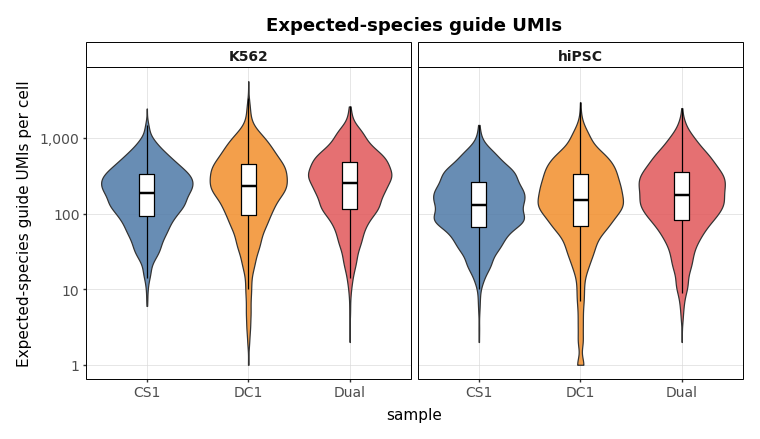

In [4]:
fig_i, source_i = plot_panel_i(result.cell_metrics)
out_i = panel_directory(ctx, "i")
outputs_i = export_matplotlib(fig_i, "i", "Figure_S02i_matched_pool_guide_recovery")
source_i_path = out_i / "Figure_S02i_matched_pool_guide_recovery_source.csv.gz"
source_i.loc[:, [
    "sample", "cell_type", "matched_pool_guide_umis",
    "K562_guide_umis", "hiPSC_guide_umis",
]].to_csv(source_i_path, compression="gzip")
diagnostic_i_path = out_i / "Figure_S02i_manuscript_median_diagnostics.csv"
result.median_diagnostics.loc[
    result.median_diagnostics["metric"].eq("matched_pool_guide_umis")
].to_csv(diagnostic_i_path, index=False)
write_receipt(
    ctx,
    "i",
    status="RESCRIPTED_SOURCE_IMPLEMENTATION",
    inputs={
        "experiment_root": str(EXPERIMENT_ROOT),
        "source_notebook": SOURCE_NOTEBOOK_LABEL,
        "source_notebook_sha256": "404daf543b4b333cf0fcbf3e553a30fad6895dc38382a27bd492f72e0d4eadb2",
    },
    outputs={
        **outputs_i,
        "source_table": str(source_i_path),
        "median_diagnostics": str(diagnostic_i_path),
    },
    parameters={
        "cell_types": list(CELL_TYPE_ORDER),
        "primers": list(CAPTURE_PRIMER_ORDER),
        "metric": "sum of guide UMIs from the pool matching transcriptomic cell type",
        "historical_medians": "diagnostic only",
    },
)
display(fig_i)


## Panel j — guide-pool specificity

Specificity is the matched-pool guide-UMI sum divided by the combined hiPSC- and K562-pool guide-UMI sum for each transcriptome-assigned cell.


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_ydensity : Removed 7 rows containing non-finite values.
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_boxplot : Removed 7 rows containing non-finite values.


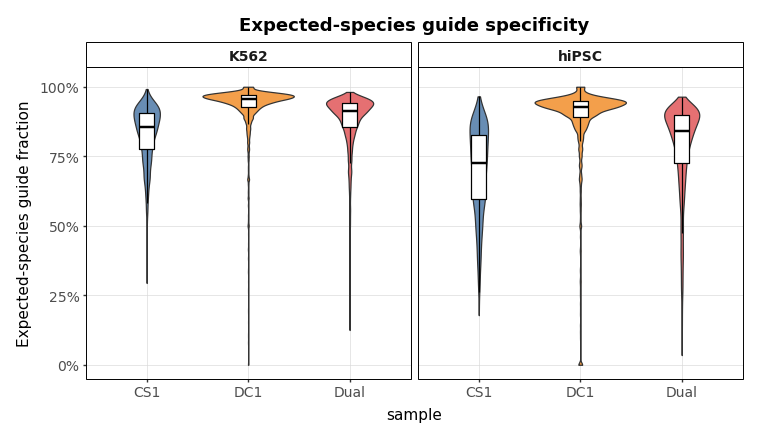

In [5]:
fig_j, source_j = plot_panel_j(result.cell_metrics)
out_j = panel_directory(ctx, "j")
outputs_j = export_matplotlib(fig_j, "j", "Figure_S02j_guide_pool_specificity")
source_j_path = out_j / "Figure_S02j_guide_pool_specificity_source.csv.gz"
source_j.loc[:, [
    "sample", "cell_type", "guide_pool_specificity",
    "matched_pool_guide_umis", "K562_guide_umis", "hiPSC_guide_umis",
]].to_csv(source_j_path, compression="gzip")
diagnostic_j_path = out_j / "Figure_S02j_manuscript_median_diagnostics.csv"
result.median_diagnostics.loc[
    result.median_diagnostics["metric"].eq("guide_pool_specificity")
].to_csv(diagnostic_j_path, index=False)
write_receipt(
    ctx,
    "j",
    status="RESCRIPTED_SOURCE_IMPLEMENTATION",
    inputs={"experiment_root": str(EXPERIMENT_ROOT)},
    outputs={
        **outputs_j,
        "source_table": str(source_j_path),
        "median_diagnostics": str(diagnostic_j_path),
    },
    parameters={
        "cell_types": list(CELL_TYPE_ORDER),
        "primers": list(CAPTURE_PRIMER_ORDER),
        "specificity": "matched-pool UMIs / (hiPSC-pool UMIs + K562-pool UMIs)",
        "zero_pool_total": "excluded as undefined",
        "historical_medians": "diagnostic only",
    },
)
display(fig_j)


## Panel l — top-guide capture

The most abundant guide UMI count per cell is shown for CS1, DC1, Dual, and the no-guide-primer background condition, separately for transcriptome-assigned K562 and hiPSC cells.


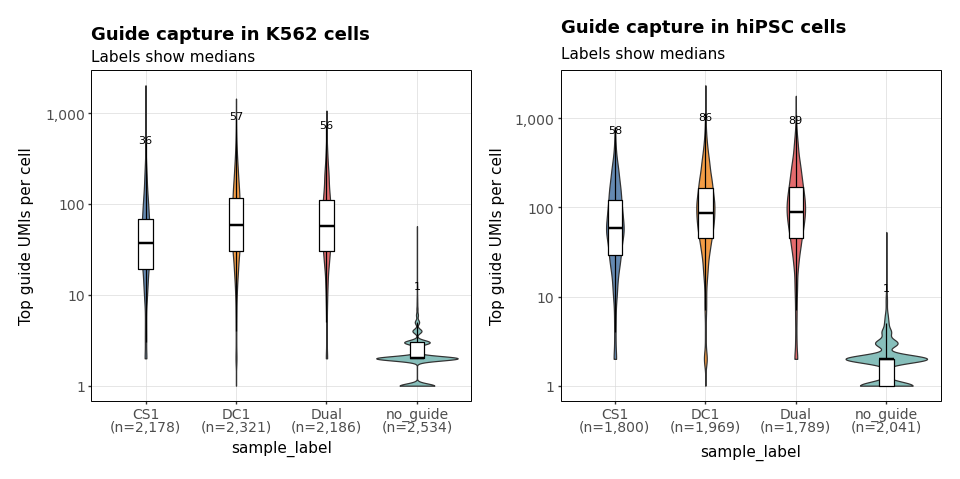

In [6]:
fig_l, source_l = plot_panel_l(result.cell_metrics)
out_l = panel_directory(ctx, "l")
outputs_l = export_matplotlib(fig_l, "l", "Figure_S02l_top_guide_umi_capture")
source_l_path = out_l / "Figure_S02l_top_guide_umi_capture_source.csv.gz"
source_l.loc[:, [
    "sample", "cell_type", "top_guide_umis", "total_guide_umis",
]].to_csv(source_l_path, compression="gzip")
write_receipt(
    ctx,
    "l",
    status="RESCRIPTED_SOURCE_IMPLEMENTATION",
    inputs={"experiment_root": str(EXPERIMENT_ROOT)},
    outputs={**outputs_l, "source_table": str(source_l_path)},
    parameters={
        "cell_types": list(CELL_TYPE_ORDER),
        "primers": list(PRIMER_ORDER),
        "metric": "maximum UMI count among valid guides in each cell",
        "no_guide_role": "background control",
    },
)
display(fig_l)


## Panel m — transcriptome recovery and saturation

The left subplot shows total transcriptome UMIs per QC-passing cell. The right subplot uses the four Split-pipe `tscp_counts_subsampled.csv` reports to plot median transcriptome UMIs per cell against mean assigned reads per cell.


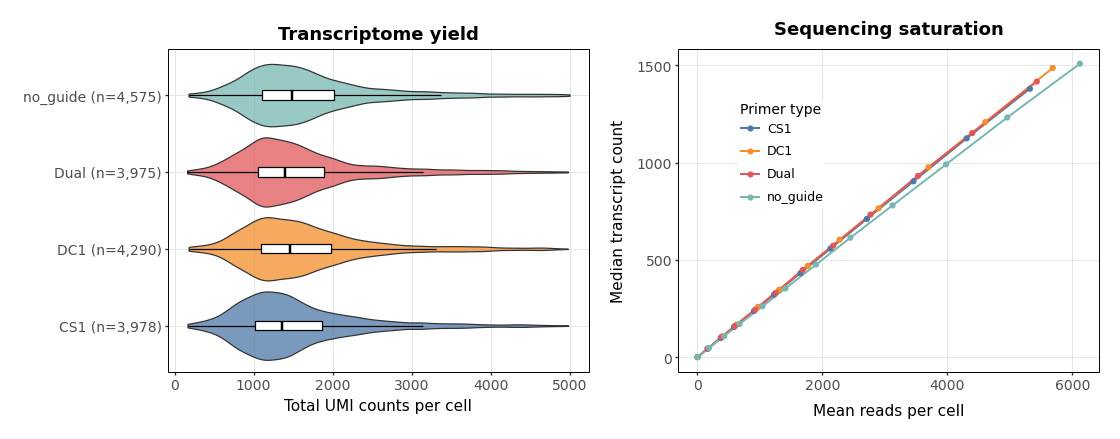

In [7]:
fig_m, transcript_m, saturation_m = plot_panel_m(
    result.cell_metrics,
    result.saturation,
)
out_m = panel_directory(ctx, "m")
outputs_m = export_matplotlib(fig_m, "m", "Figure_S02m_transcriptome_recovery_and_saturation")
transcript_m_path = out_m / "Figure_S02m_transcriptome_UMI_source.csv.gz"
saturation_m_path = out_m / "Figure_S02m_transcript_saturation_source.csv"
transcript_m.to_csv(transcript_m_path, compression="gzip")
saturation_m.to_csv(saturation_m_path, index=False)
write_receipt(
    ctx,
    "m",
    status="RESCRIPTED_SOURCE_IMPLEMENTATION",
    inputs={"experiment_root": str(EXPERIMENT_ROOT)},
    outputs={
        **outputs_m,
        "transcript_source_table": str(transcript_m_path),
        "saturation_source_table": str(saturation_m_path),
    },
    parameters={
        "primer_order": list(MANUSCRIPT_TRANSCRIPT_ORDER),
        "left_metric": "total transcriptome UMIs per QC-passing cell",
        "right_x": "mean assigned reads per cell from Split-pipe report",
        "right_y": "median transcriptome UMIs per cell from Split-pipe report",
    },
)
display(fig_m)


## Panel n — guide-pool mixing

Individual cell-guide observations below 3 UMIs are set to zero before summing the hiPSC- and K562-pool guide counts per cell. The two-dimensional histogram and marginal histograms show the resulting distribution of guide-pool UMIs across cells.


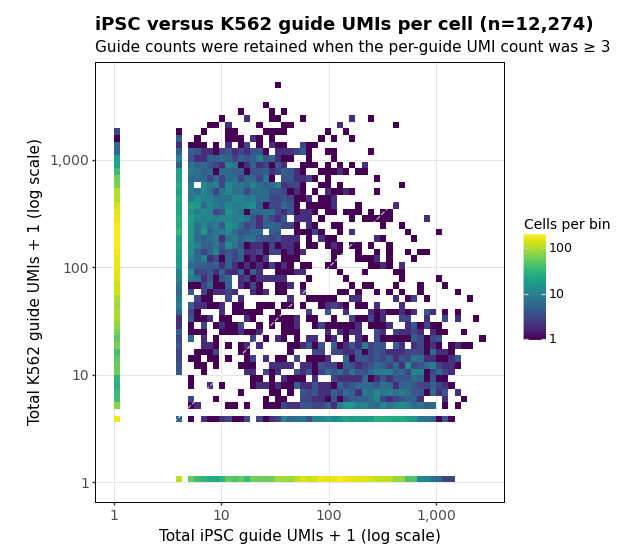

In [8]:
fig_n, source_n = plot_panel_n(result.cell_metrics)
out_n = panel_directory(ctx, "n")
outputs_n = export_matplotlib(fig_n, "n", "Figure_S02n_guide_pool_mixing")
source_n_path = out_n / "Figure_S02n_guide_pool_mixing_source.csv.gz"
source_n.to_csv(source_n_path, compression="gzip")
write_receipt(
    ctx,
    "n",
    status="RESCRIPTED_SOURCE_IMPLEMENTATION",
    inputs={"experiment_root": str(EXPERIMENT_ROOT)},
    outputs={**outputs_n, "source_table": str(source_n_path)},
    parameters={
        "cell_guide_minimum_umis": 3,
        "x": "sum of retained hiPSC-pool guide UMIs per cell + 1",
        "y": "sum of retained K562-pool guide UMIs per cell + 1",
        "axes": "logarithmic",
        "color": "log-normalized cell count per 2D bin",
    },
)
display(fig_n)


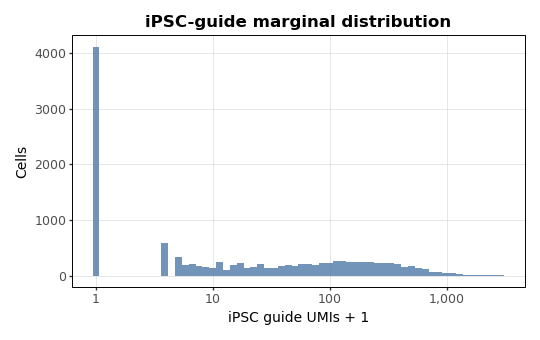

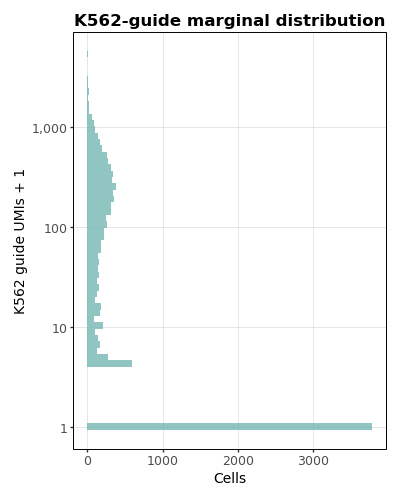

In [9]:
from cc_perturbseq.figure_s02_parse_mix import plot_panel_n_marginals
for label, figure in zip(("iPSC","K562"),plot_panel_n_marginals(result.cell_metrics)):
    export_matplotlib(figure,"n",f"Figure_S02n_{label}_marginal")
    display(figure)


## Outputs

Vector and raster figures, source tables, and run receipts are written under `outputs.root/Figure_S02/panel_<letter>/`. The output root is defined by the repository path configuration.


In [10]:
print("Figure S2 mixed-cell outputs:", ctx["output_dir"])
for panel in ("i", "j", "l", "m", "n"):
    print(panel, panel_directory(ctx, panel))


Figure S2 mixed-cell outputs: /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S02
i /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S02/panel_i
j /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S02/panel_j
l /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S02/panel_l
m /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S02/panel_m
n /scratch/users/edtng/cc_perturbseq_manuscript_figures/Figure_S02/panel_n
